In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [2]:
PATH = "Used_Car_Price_Data.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()

print("Shape:", df.shape)
df.head()

Shape: (1000, 6)


,Name,Price($),Milage,Review,Review_count,Badge
0,2021 Toyota Camry SE,"31,150","13,390",4.5,659,Good Deal
1,2021 Toyota Supra 3.0 Premium,"58,981","7,348",4.8,"2,744",Great Deal
2,2019 Toyota Sequoia Platinum,"51,999","55,121",4.5,"2,092",Great Deal
3,2019 Toyota Camry SE,"25,689","49,126",1.0,1,Good Deal
4,2017 Toyota Highlander Limited,"31,591","84,621",4.9,"1,745",Good Deal


In [3]:
df.info()
print()
print("Missing value per kolom:")
print(df.isna().sum())
print("\nDuplikat:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Name          1000 non-null   str    
 1   Price($)      1000 non-null   str    
 2   Milage        1000 non-null   str    
 3   Review        997 non-null    float64
 4   Review_count  1000 non-null   str    
 5   Badge         977 non-null    str    
dtypes: float64(1), str(5)
memory usage: 47.0 KB

Missing value per kolom:
Name             0
Price($)         0
Milage           0
Review           3
Review_count     0
Badge           23
dtype: int64

Duplikat: 0


In [4]:
# 3.1 Rapikan nama kolom
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"\(\$\)", "", regex=True)
              .str.replace("milage", "mileage"))      # typo pada data asli
print(df.columns.tolist())

['name', 'price', 'mileage', 'review', 'review_count', 'badge']


In [5]:
# 3.2 Ubah kolom numerik yang tersimpan sebagai string ("31,150") menjadi angka
for col in ["price", "mileage", "review_count"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False).str.strip(),
                            errors="coerce")

# 3.3 Rapikan teks (spasi berlebih, mis. "Good Deal " vs "Good Deal")
for col in ["name", "badge"]:
    df[col] = df[col].astype("string").str.strip()

df[["price", "mileage", "review_count"]].dtypes

price           int64
mileage         int64
review_count    int64
dtype: object

In [6]:
# 3.4 Missing value & duplikat
print("Missing sebelum:\n", df.isna().sum(), "\n")

df = df.drop_duplicates().reset_index(drop=True)

# badge kosong = mobil tanpa label khusus -> kategori sendiri
df["badge"] = df["badge"].fillna("No Badge")

# review kosong (hanya sedikit) diimputasi median setelah split (lihat bagian Preprocessing),
# di sini hanya dibuat flag agar informasinya tidak hilang
df["review_missing"] = df["review"].isna().astype(int)

print("Missing sesudah:\n", df.isna().sum())
print("Shape:", df.shape)

Missing sebelum:
 name             0
price            0
mileage          0
review           3
review_count     0
badge           23
dtype: int64 

Missing sesudah:
 name              0
price             0
mileage           0
review            3
review_count      0
badge             0
review_missing    0
dtype: int64
Shape: (1000, 7)


In [7]:
# Name berformat: "<year> <brand> <model> <trim...>"  ->  pecah menjadi fitur terpisah
parts = df["name"].str.split()
df["year"]  = parts.str[0].astype(int)
df["brand"] = parts.str[1]

# Model "Land Cruiser" & "FJ Cruiser" terdiri dari 2 kata
two_word = parts.str[2].isin(["Land", "FJ"])
df["model"] = np.where(two_word, parts.str[2] + " " + parts.str[3], parts.str[2])
df["trim"]  = np.where(two_word, parts.str[4:].str.join(" "), parts.str[3:].str.join(" "))
df["trim"]  = df["trim"].replace("", "Base")

# Fitur turunan
CURRENT_YEAR = 2021 + 1                       # tahun model terbaru pada data + 1
df["age"] = CURRENT_YEAR - df["year"]
df["mileage_per_year"] = df["mileage"] / df["age"]
df["log_price"] = np.log1p(df["price"])       # target alternatif (distribusi price right-skewed)

print(df["brand"].unique())                   # semua Toyota -> tidak informatif
df[["name", "year", "model", "trim", "age", "mileage", "mileage_per_year", "price"]].head()

['Toyota']


,name,year,model,trim,age,mileage,mileage_per_year,price
0,2021 Toyota Camry SE,2021,Camry,SE,1,13390,13390.000000,31150
1,2021 Toyota Supra 3.0 Premium,2021,Supra,3.0 Premium,1,7348,7348.000000,58981
2,2019 Toyota Sequoia Platinum,2019,Sequoia,Platinum,3,55121,18373.666667,51999
3,2019 Toyota Camry SE,2019,Camry,SE,3,49126,16375.333333,25689
4,2017 Toyota Highlander Limited,2017,Highlander,Limited,5,84621,16924.200000,31591


In [8]:
# Grouping model langka supaya one-hot tidak terlalu sparse
top_models = df["model"].value_counts()
rare = top_models[top_models < 15].index
df["model_grp"] = df["model"].where(~df["model"].isin(rare), "Other")

print(df["model_grp"].value_counts())

model_grp
RAV4            262
Highlander      171
Camry           135
4Runner         125
Corolla          75
Tundra           56
Tacoma           43
Other            42
Sienna           25
Prius            25
C-HR             23
Land Cruiser     18
Name: count, dtype: int64


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,1000.0,31557.029000,12012.067275,3998.0000,24305.500000,29989.500000,38829.250000,122755.000000
mileage,1000.0,47881.702000,38190.403080,596.0000,21380.500000,37108.000000,60690.500000,293420.000000
review,997.0,4.448847,0.591702,1.0000,4.400000,4.600000,4.800000,5.000000
review_count,1000.0,1041.246000,1488.018173,0.0000,145.000000,585.500000,1391.500000,25582.000000
review_missing,1000.0,0.003000,0.054717,0.0000,0.000000,0.000000,0.000000,1.000000
year,1000.0,2017.435000,3.253361,1998.0000,2017.000000,2018.000000,2019.000000,2021.000000
age,1000.0,4.565000,3.253361,1.0000,3.000000,4.000000,5.000000,24.000000
mileage_per_year,1000.0,10991.853459,5617.980914,500.0000,7350.250000,9803.583333,13754.375000,46960.000000
log_price,1000.0,10.284314,0.408096,8.2938,10.098499,10.308636,10.566955,11.717954


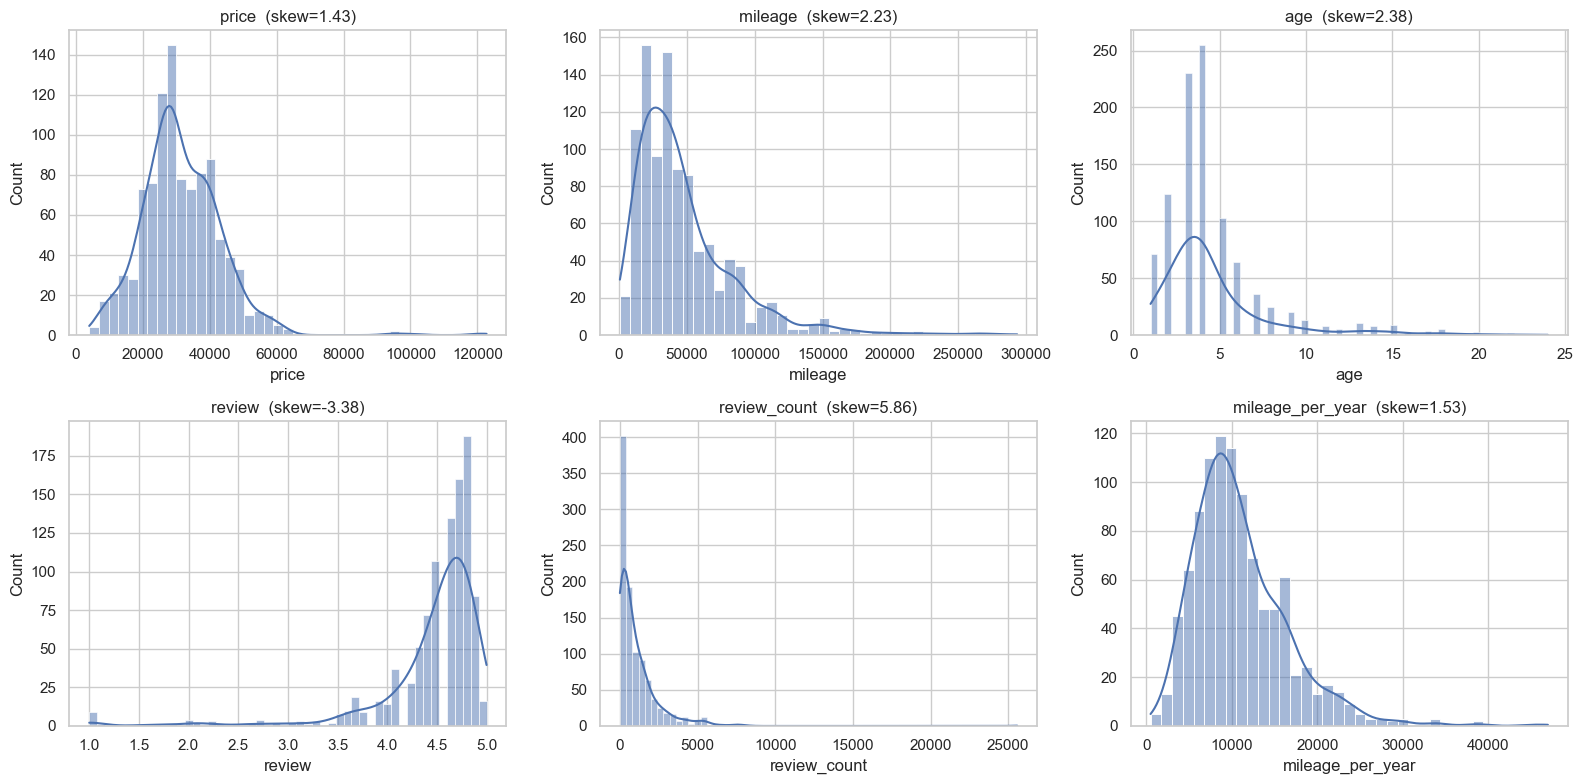

In [10]:
# 5.1 Distribusi variabel numerik
num_cols = ["price", "mileage", "age", "review", "review_count", "mileage_per_year"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(f"{c}  (skew={df[c].skew():.2f})")
plt.tight_layout(); plt.show()

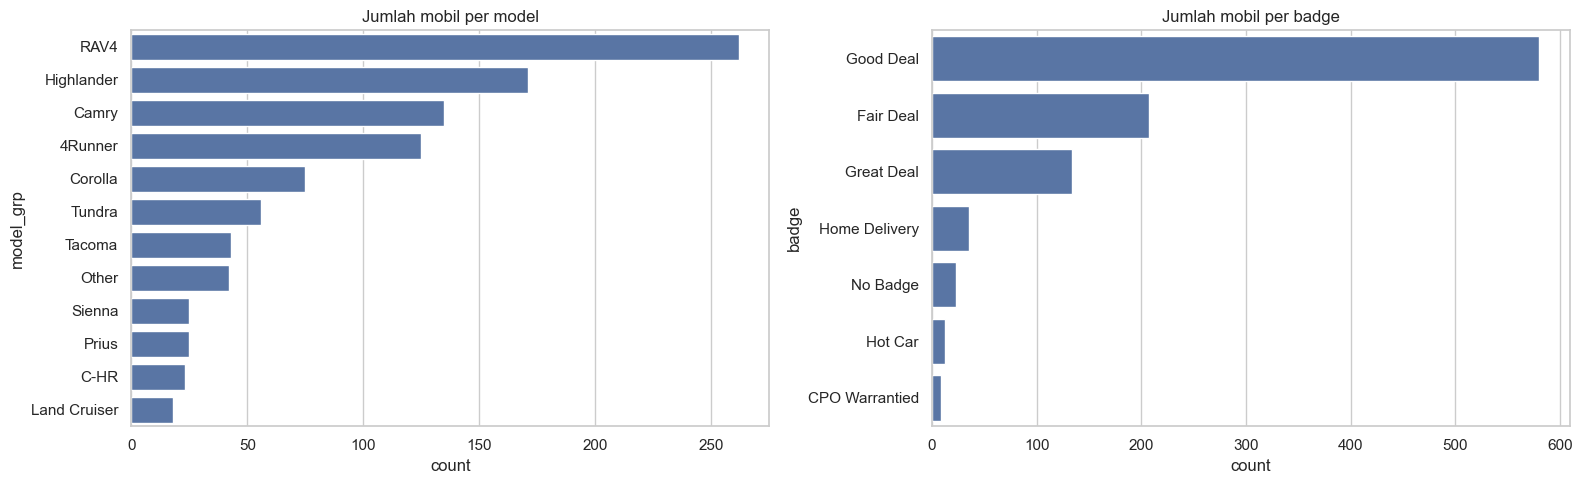

In [11]:
# 5.2 Distribusi variabel kategorikal
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(y="model_grp", data=df, order=df["model_grp"].value_counts().index, ax=axes[0])
axes[0].set_title("Jumlah mobil per model")
sns.countplot(y="badge", data=df, order=df["badge"].value_counts().index, ax=axes[1])
axes[1].set_title("Jumlah mobil per badge")
plt.tight_layout(); plt.show()

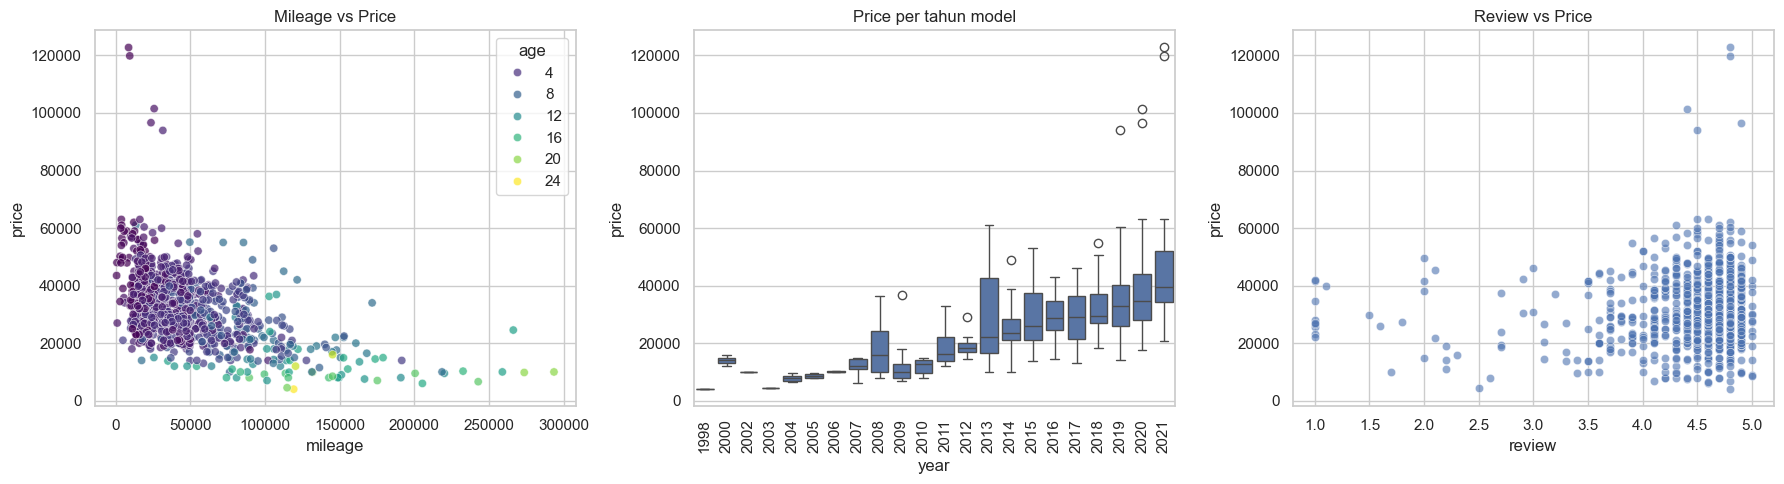

In [12]:
# 5.3 Hubungan fitur vs price
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x="mileage", y="price", hue="age", data=df, palette="viridis", ax=axes[0], alpha=.7)
axes[0].set_title("Mileage vs Price")
sns.boxplot(x="year", y="price", data=df, ax=axes[1])
axes[1].set_title("Price per tahun model"); axes[1].tick_params(axis="x", rotation=90)
sns.scatterplot(x="review", y="price", data=df, ax=axes[2], alpha=.6)
axes[2].set_title("Review vs Price")
plt.tight_layout(); plt.show()

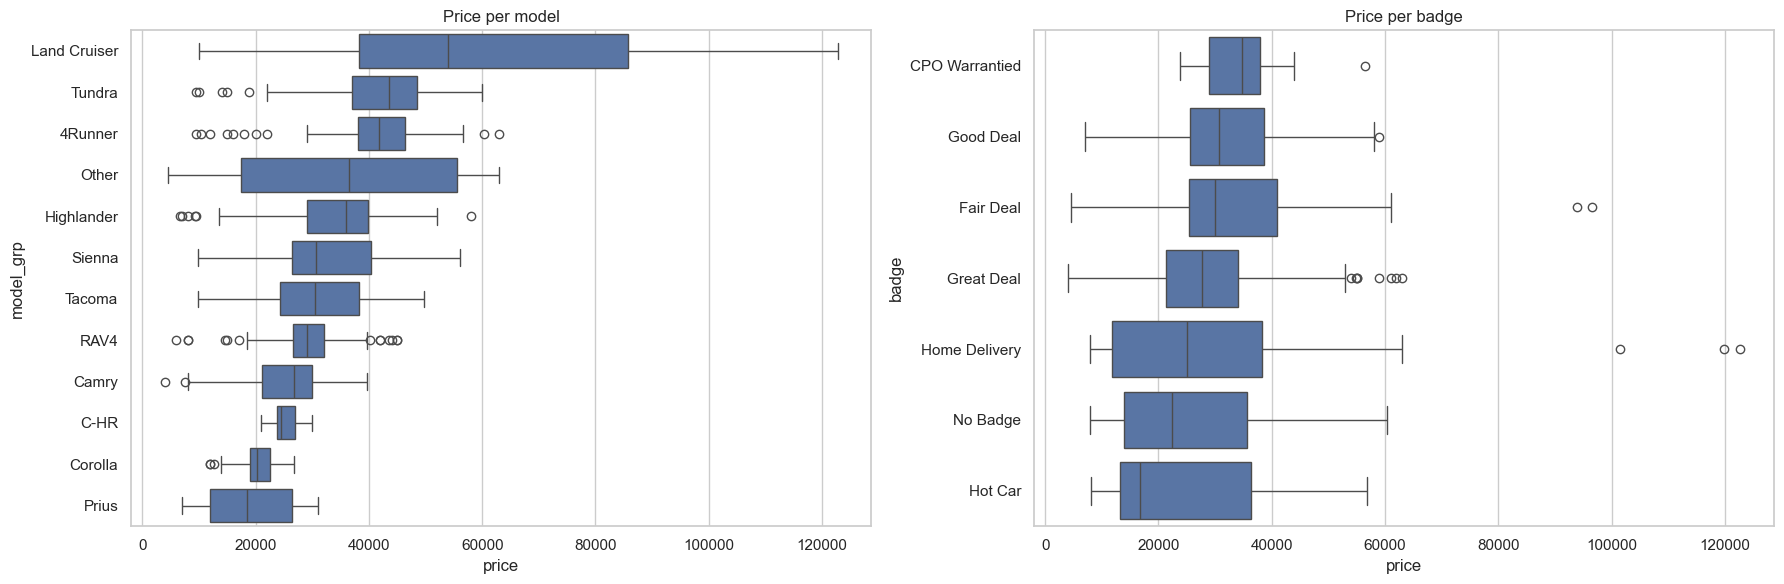

In [13]:
# 5.4 Price per model & badge
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
order = df.groupby("model_grp")["price"].median().sort_values(ascending=False).index
sns.boxplot(y="model_grp", x="price", data=df, order=order, ax=axes[0])
axes[0].set_title("Price per model")
order_b = df.groupby("badge")["price"].median().sort_values(ascending=False).index
sns.boxplot(y="badge", x="price", data=df, order=order_b, ax=axes[1])
axes[1].set_title("Price per badge")
plt.tight_layout(); plt.show()

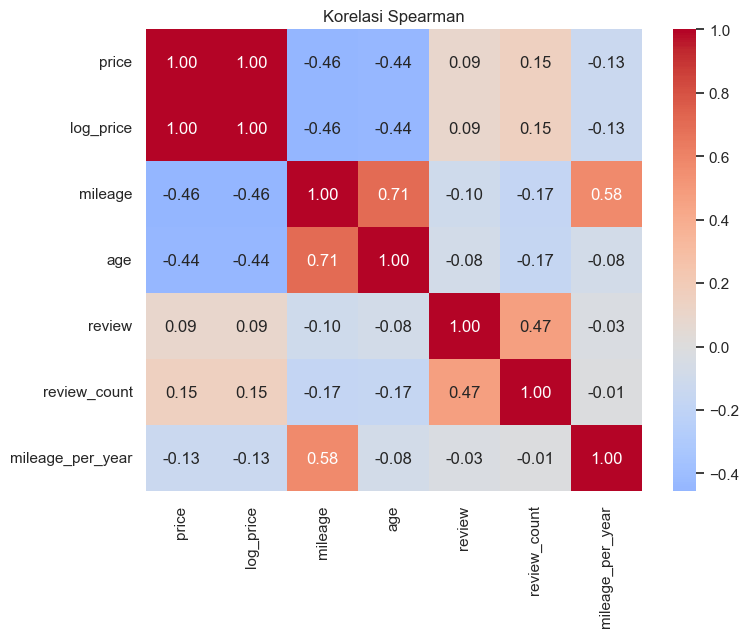

In [14]:
# 5.5 Korelasi antar variabel numerik
corr = df[["price", "log_price", "mileage", "age", "review", "review_count", "mileage_per_year"]].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi Spearman"); plt.show()

In [15]:
# 6.1 Uji normalitas target (price vs log_price)
for c in ["price", "log_price"]:
    stat, p = stats.normaltest(df[c])
    print(f"{c:10s} skew={df[c].skew():5.2f}  kurtosis={df[c].kurt():6.2f}  normaltest p={p:.4g}")

price      skew= 1.43  kurtosis=  7.92  normaltest p=6.186e-79
log_price  skew=-0.91  kurtosis=  2.31  normaltest p=4.777e-36


In [16]:
# 6.2 Signifikansi korelasi numerik terhadap price (Spearman)
rows = []
for c in ["mileage", "age", "review", "review_count", "mileage_per_year"]:
    sub = df[[c, "price"]].dropna()
    rho, p = stats.spearmanr(sub[c], sub["price"])
    rows.append([c, rho, p])
pd.DataFrame(rows, columns=["fitur", "spearman_rho", "p_value"]).sort_values("spearman_rho", key=abs, ascending=False)

,fitur,spearman_rho,p_value
0,mileage,-0.457056,9.082415e-53
1,age,-0.444769,9.641395e-50
3,review_count,0.146351,3.363284e-06
4,mileage_per_year,-0.133073,2.425090e-05
2,review,0.093103,3.256122e-03


In [17]:
# 6.3 Apakah price berbeda signifikan antar kategori? (Kruskal-Wallis)
for c in ["model_grp", "badge", "year"]:
    groups = [g["price"].values for _, g in df.groupby(c) if len(g) > 1]
    h, p = stats.kruskal(*groups)
    print(f"{c:10s} H={h:8.2f}  p-value={p:.3g}  -> {'berbeda signifikan' if p < .05 else 'tidak signifikan'}")

model_grp  H=  397.47  p-value=2.11e-78  -> berbeda signifikan
badge      H=   29.17  p-value=5.65e-05  -> berbeda signifikan
year       H=  252.17  p-value=1.13e-42  -> berbeda signifikan


In [18]:
# 6.4 Deteksi outlier (IQR) pada variabel numerik
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - k*iqr) | (s > q3 + k*iqr)

summary = pd.DataFrame({
    "n_outlier": {c: iqr_outliers(df[c]).sum() for c in ["price", "mileage", "mileage_per_year", "review_count"]}
})
summary["pct"] = (summary["n_outlier"] / len(df) * 100).round(2)
print(summary)

# Data yang tampak janggal
print("\nPrice > 80.000 :"); display(df.loc[df["price"] > 80_000, ["name", "price", "mileage"]])
print("Mileage > 200.000 :"); display(df.loc[df["mileage"] > 200_000, ["name", "price", "mileage"]])

                  n_outlier  pct
price                    10  1.0
mileage                  45  4.5
mileage_per_year         31  3.1
review_count             62  6.2

Price > 80.000 :


,name,price,mileage
73,2020 Toyota Land Cruiser Heritage Edition,101500,25727
94,2021 Toyota Land Cruiser Base,119855,9383
167,2021 Toyota Land Cruiser,122755,8609
794,2020 Toyota Land Cruiser Base,96626,23597
986,2019 Toyota Land Cruiser V8,93935,31529


Mileage > 200.000 :


,name,price,mileage
89,2002 Toyota Tacoma PreRunner,9800,273500
144,2002 Toyota Land Cruiser,9988,293420
188,2004 Toyota 4Runner SR5,9500,200439
263,2010 Toyota Tundra,9499,220022
307,2006 Toyota 4Runner Sport,10260,232537
338,2013 Toyota Tundra Grade,9995,218460
433,2007 Toyota RAV4 Base,5999,205324
490,2008 Toyota Land Cruiser,24545,266178
540,2004 Toyota Highlander,6600,242684
634,2008 Toyota Sequoia Limited,9995,258855


,count,median,mean
age,,,
1,71,39624.0,43844.0
2,124,34620.0,36516.0
3,230,32810.0,33809.0
4,255,29474.0,31899.0
5,103,28987.0,28856.0
6,64,28746.0,28403.0
7,36,25992.0,28051.0
8,25,23412.0,24767.0
9,20,21990.0,28812.0


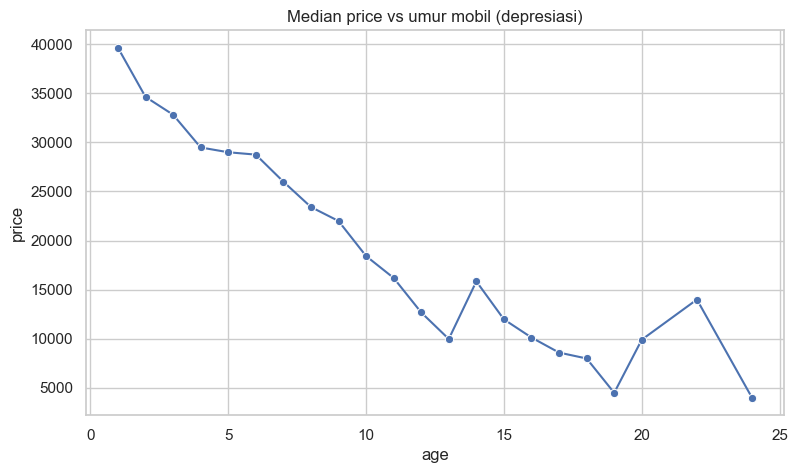

In [19]:
# 6.5 Depresiasi: rata-rata price per umur mobil
dep = df.groupby("age")["price"].agg(["count", "median", "mean"]).round(0)
display(dep)

plt.figure(figsize=(9, 5))
sns.lineplot(x="age", y="price", data=df, estimator="median", errorbar=None, marker="o")
plt.title("Median price vs umur mobil (depresiasi)"); plt.show()

In [20]:
# 6.6 Apakah badge hanya mencerminkan harga? (potensi data leakage)
print(df.groupby("badge")["price"].describe()[["count", "mean", "50%"]].round(0))

                count     mean      50%
badge                                  
CPO Warrantied    9.0  35525.0  34734.0
Fair Deal       207.0  33222.0  29995.0
Good Deal       580.0  31776.0  30620.0
Great Deal      134.0  28776.0  27697.0
Home Delivery    35.0  33618.0  24950.0
Hot Car          12.0  24561.0  16743.0
No Badge         23.0  26227.0  22450.0


In [21]:
# 7.1 Penanganan outlier ekstrem (di atas persentil 99,5)
before = len(df)
df_model = df[(df["price"] <= df["price"].quantile(0.995)) &
              (df["mileage"] <= df["mileage"].quantile(0.995))].copy()
print(f"Baris dibuang: {before - len(df_model)}  |  sisa: {len(df_model)}")

Baris dibuang: 10  |  sisa: 990


In [22]:
# 7.2 Tentukan target & fitur
# Badge ("Great Deal", dst.) dihitung platform dari harga vs nilai pasar -> mengandung info target (leakage),
# sehingga TIDAK dipakai sebagai fitur. Ubah USE_BADGE=True bila ingin membandingkan.
USE_BADGE = False

TARGET = "price"
num_features = ["mileage", "age", "review", "review_count", "mileage_per_year", "review_missing"]
cat_features = ["model_grp", "trim"]
if USE_BADGE:
    cat_features.append("badge")

X = df_model[num_features + cat_features]
y = np.log1p(df_model[TARGET])          # model dilatih pada log(price), prediksi di-balik dengan expm1
print(X.shape, y.shape)

(990, 8) (990,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (792, 8) | Test: (198, 8)


In [24]:
# 8.1 Pipeline preprocessing (fit hanya pada train -> tidak ada leakage)
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5)),   # trim langka digabung otomatis
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", categorical_pipe, cat_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [25]:
# 9.1 Fungsi evaluasi (metrik dihitung pada skala harga asli, bukan log)
def evaluate(model, X_te, y_te_log):
    pred = np.expm1(model.predict(X_te))
    true = np.expm1(y_te_log)
    return {
        "MAE":  mean_absolute_error(true, pred),
        "RMSE": np.sqrt(mean_squared_error(true, pred)),
        "R2":   r2_score(true, pred),
        "MAPE%": np.mean(np.abs((true - pred) / true)) * 100,
    }

models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   random_state=RANDOM_STATE),
}
pipes = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}

In [26]:
# 9.2 Cross-validation (5-fold) pada data train
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in pipes.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1)
    cv_rows.append([name, scores.mean(), scores.std()])
cv_df = pd.DataFrame(cv_rows, columns=["model", "cv_r2_mean(log)", "cv_r2_std"]).sort_values("cv_r2_mean(log)", ascending=False)
cv_df

,model,cv_r2_mean(log),cv_r2_std
1,Ridge,0.869035,0.041814
0,Linear Regression,0.868037,0.044329
3,Gradient Boosting,0.856676,0.029103
2,Random Forest,0.834038,0.032500


In [27]:
# 9.3 Training & evaluasi pada data test
results = {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    results[name] = evaluate(pipe, X_test, y_test)

results_df = pd.DataFrame(results).T.sort_values("R2", ascending=False).round(3)
results_df

,MAE,RMSE,R2,MAPE%
Gradient Boosting,2374.475,3347.513,0.904,8.180
Ridge,2485.172,3505.298,0.895,8.401
Linear Regression,2497.088,3541.689,0.893,8.412
Random Forest,2563.143,3680.862,0.884,8.973


In [28]:
# 9.4 Hyperparameter tuning pada Gradient Boosting
param_dist = {
    "model__n_estimators":      [200, 300, 500, 800],
    "model__learning_rate":     [0.01, 0.03, 0.05, 0.1],
    "model__max_depth":         [2, 3, 4, 5],
    "model__min_samples_leaf":  [1, 3, 5, 10],
    "model__subsample":         [0.7, 0.85, 1.0],
}
search = RandomizedSearchCV(
    pipes["Gradient Boosting"], param_dist, n_iter=25, cv=kf,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
best_model = search.best_estimator_
print({k: round(v, 3) for k, v in evaluate(best_model, X_test, y_test).items()})

Best params: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_depth': 3, 'model__learning_rate': 0.1}
{'MAE': 2526.869, 'RMSE': np.float64(3612.879), 'R2': 0.888, 'MAPE%': np.float64(8.839)}


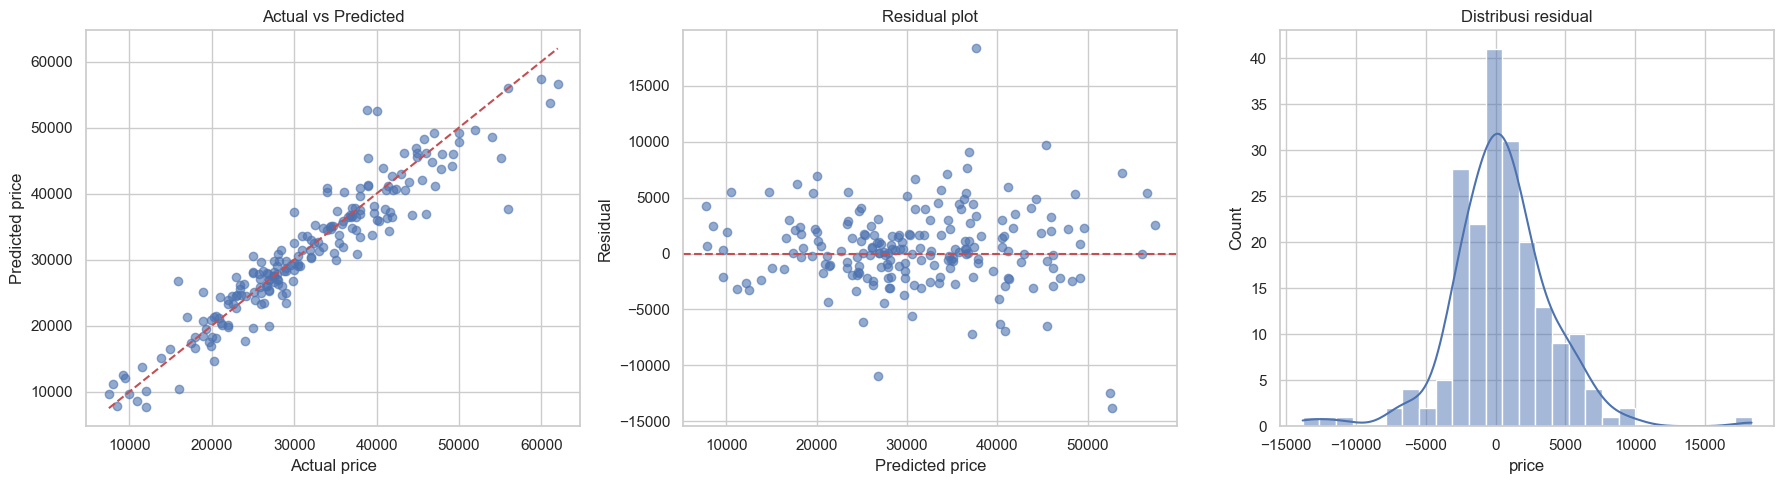

In [29]:
pred = np.expm1(best_model.predict(X_test))
true = np.expm1(y_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(true, pred, alpha=.6)
axes[0].plot([true.min(), true.max()], [true.min(), true.max()], "r--")
axes[0].set(xlabel="Actual price", ylabel="Predicted price", title="Actual vs Predicted")

resid = true - pred
axes[1].scatter(pred, resid, alpha=.6); axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Predicted price", ylabel="Residual", title="Residual plot")

sns.histplot(resid, kde=True, ax=axes[2]); axes[2].set_title("Distribusi residual")
plt.tight_layout(); plt.show()

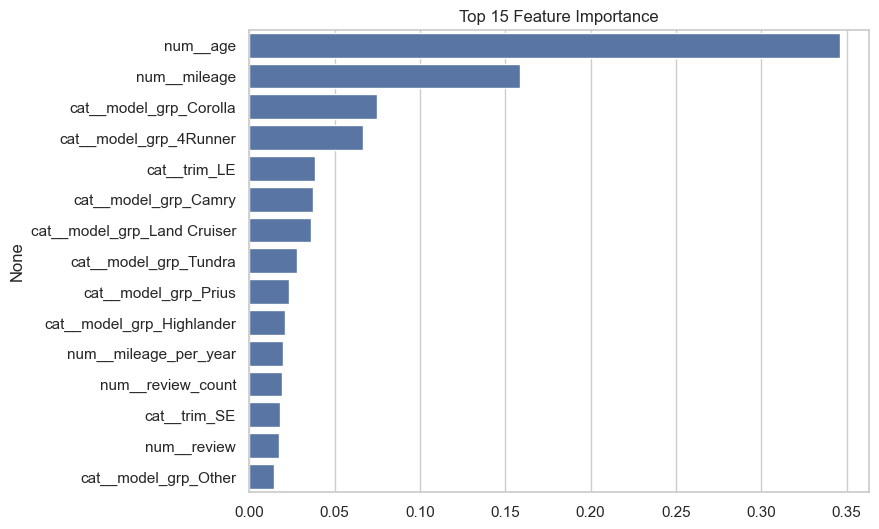

In [30]:
# Feature importance (Gradient Boosting)
feat_names = best_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_model.named_steps["model"].feature_importances_, index=feat_names)
imp = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Top 15 Feature Importance"); plt.show()

In [31]:
# Simpan model & contoh prediksi
import joblib
joblib.dump(best_model, "used_car_price_model.joblib")

sample = pd.DataFrame([{
    "mileage": 40000, "age": 4, "review": 4.6, "review_count": 500,
    "mileage_per_year": 10000, "review_missing": 0,
    "model_grp": "RAV4", "trim": "XLE",
}])[X.columns]
print(f"Prediksi harga: ${np.expm1(best_model.predict(sample))[0]:,.0f}")

Prediksi harga: $28,157


In [32]:
# 11.1 Pilih model final & simpan artefak (model, metadata, data referensi untuk monitoring)
import json, joblib, sklearn, datetime
from pathlib import Path

DEPLOY_DIR = Path("deployment")
DEPLOY_DIR.mkdir(exist_ok=True)

# Model final = RMSE test terendah di antara semua model yang sudah dilatih
candidates = {**pipes, "Gradient Boosting (tuned)": best_model}
scores = {name: evaluate(m, X_test, y_test) for name, m in candidates.items()}
best_name = min(scores, key=lambda n: scores[n]["RMSE"])
final_model = candidates[best_name]
print("Model final:", best_name)
print(pd.DataFrame(scores).T.round(3))

metadata = {
    "model_name": best_name,
    "model_version": "1.0.0",
    "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "target": "price (USD); model dilatih pada log1p(price)",
    "num_features": num_features,
    "cat_features": cat_features,
    "current_year": CURRENT_YEAR,
    "known_model_groups": sorted(X["model_grp"].unique().tolist()),
    "input_limits": {
        "year": [int(df["year"].min()), int(df["year"].max())],
        "mileage": [0, int(df["mileage"].max())],
        "review": [0.0, 5.0],
    },
    "test_metrics": {k: round(float(v), 4) for k, v in scores[best_name].items()},
}

joblib.dump(final_model, DEPLOY_DIR / "used_car_model.joblib")
(DEPLOY_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))

# Data referensi (distribusi training) untuk deteksi drift pada tahap monitoring
reference = X_train.copy()
reference["price"] = np.expm1(y_train)
reference.to_csv(DEPLOY_DIR / "reference_data.csv", index=False)

print("\nArtefak tersimpan:", sorted(p.name for p in DEPLOY_DIR.iterdir()))

Model final: Gradient Boosting
                                MAE      RMSE     R2  MAPE%
Linear Regression          2497.088  3541.689  0.893  8.412
Ridge                      2485.172  3505.298  0.895  8.401
Random Forest              2563.143  3680.862  0.884  8.973
Gradient Boosting          2374.475  3347.513  0.904  8.180
Gradient Boosting (tuned)  2526.869  3612.879  0.888  8.839

Artefak tersimpan: ['model_metadata.json', 'reference_data.csv', 'used_car_model.joblib']


In [33]:
# 11.2 Modul inferensi (predictor.py): validasi input + feature engineering yang SAMA dengan training
PREDICTOR = '''"""predictor.py - logika inferensi model harga mobil bekas."""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

BASE_DIR = Path(__file__).resolve().parent
MODEL = joblib.load(BASE_DIR / "used_car_model.joblib")
META = json.loads((BASE_DIR / "model_metadata.json").read_text())
FEATURES = META["num_features"] + META["cat_features"]
_GROUPS = {g.lower(): g for g in META["known_model_groups"]}


class ValidationError(ValueError):
    """Input pengguna tidak valid."""


def _to_float(value, name):
    try:
        return float(value)
    except (TypeError, ValueError):
        raise ValidationError(f"{name} harus berupa angka")


def build_features(payload: dict) -> pd.DataFrame:
    """Ubah input mentah menjadi fitur yang dipakai saat training."""
    missing = [k for k in ("year", "mileage", "model") if payload.get(k) in (None, "")]
    if missing:
        raise ValidationError(f"Field wajib belum diisi: {missing}")

    year = int(_to_float(payload["year"], "year"))
    mileage = _to_float(payload["mileage"], "mileage")
    lo, hi = META["input_limits"]["year"]
    if not lo <= year <= hi:
        raise ValidationError(f"year harus antara {lo} dan {hi}")
    if not 0 <= mileage <= META["input_limits"]["mileage"][1] * 1.5:
        raise ValidationError("mileage di luar rentang yang wajar")

    review = payload.get("review")
    review = np.nan if review in (None, "") else _to_float(review, "review")
    if not np.isnan(review) and not 0 <= review <= 5:
        raise ValidationError("review harus antara 0 dan 5")
    review_count = payload.get("review_count")
    review_count = np.nan if review_count in (None, "") else _to_float(review_count, "review_count")

    age = META["current_year"] - year
    model = str(payload["model"]).strip()
    trim = str(payload.get("trim") or "").strip() or "Base"

    row = {
        "mileage": mileage,
        "age": age,
        "review": review,
        "review_count": review_count,
        "mileage_per_year": mileage / age,
        "review_missing": int(np.isnan(review)),
        "model_grp": _GROUPS.get(model.lower(), "Other"),
        "trim": trim,
    }
    return pd.DataFrame([row])[FEATURES]


def predict_features(features: pd.DataFrame) -> np.ndarray:
    """Prediksi harga (USD) dari DataFrame fitur yang sudah siap."""
    return np.expm1(MODEL.predict(features))


def predict(payload: dict) -> dict:
    price = float(predict_features(build_features(payload))[0])
    mae = META["test_metrics"]["MAE"]
    return {
        "predicted_price": round(price, 2),
        "currency": "USD",
        "estimated_range": [round(max(price - mae, 0), 2), round(price + mae, 2)],
        "model_version": META["model_version"],
    }
'''
(DEPLOY_DIR / "predictor.py").write_text(PREDICTOR)
print("predictor.py ditulis,", len(PREDICTOR.splitlines()), "baris")

predictor.py ditulis, 78 baris


In [34]:
# 11.3 Uji modul inferensi (sebelum dipasang ke API)
import sys
sys.path.insert(0, str(DEPLOY_DIR.resolve()))
import predictor

contoh = {"year": 2019, "mileage": 55000, "model": "RAV4", "trim": "XLE", "review": 4.6, "review_count": 500}
print(predictor.predict(contoh))

# Input tidak valid harus ditolak dengan pesan yang jelas
try:
    predictor.predict({"year": 2035, "mileage": 1000, "model": "Camry"})
except predictor.ValidationError as e:
    print("Ditolak:", e)

{'predicted_price': 30315.16, 'currency': 'USD', 'estimated_range': [27940.69, 32689.64], 'model_version': '1.0.0'}
Ditolak: year harus antara 1998 dan 2021


In [35]:
# 11.4 REST API dengan Flask (app.py): /health, /predict, /feedback + logging untuk monitoring
APP = '''"""app.py - REST API prediksi harga mobil bekas."""
import csv
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

from flask import Flask, jsonify, request

import predictor

app = Flask(__name__)
LOG_DIR = Path(__file__).resolve().parent / "logs"
LOG_DIR.mkdir(exist_ok=True)
PRED_LOG = LOG_DIR / "predictions_log.csv"
FEEDBACK_LOG = LOG_DIR / "feedback_log.csv"
PRED_COLS = ["request_id", "timestamp", "status", "latency_ms", "year", "mileage",
             "model", "trim", "review", "review_count", "predicted_price"]
FB_COLS = ["request_id", "timestamp", "actual_price"]


def _append(path, cols, row):
    new_file = not path.exists()
    with path.open("a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=cols)
        if new_file:
            writer.writeheader()
        writer.writerow({c: row.get(c, "") for c in cols})


def _now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")


@app.get("/health")
def health():
    return jsonify(status="ok", model=predictor.META["model_name"],
                   version=predictor.META["model_version"])


@app.post("/predict")
def predict():
    start = time.perf_counter()
    payload = request.get_json(silent=True) or {}
    rid = str(uuid.uuid4())
    log = {"request_id": rid, "timestamp": _now(), **{k: payload.get(k, "") for k in
           ("year", "mileage", "model", "trim", "review", "review_count")}}
    try:
        result = predictor.predict(payload)
        status, code = "ok", 200
        log["predicted_price"] = result["predicted_price"]
        body = {"request_id": rid, **result}
    except predictor.ValidationError as e:
        status, code, body = "invalid_input", 400, {"error": str(e)}
    except Exception as e:  # kesalahan tak terduga
        status, code, body = "server_error", 500, {"error": "internal error"}
    log["status"] = status
    log["latency_ms"] = round((time.perf_counter() - start) * 1000, 2)
    _append(PRED_LOG, PRED_COLS, log)
    return jsonify(body), code


@app.post("/feedback")
def feedback():
    """Terima harga jual sebenarnya agar performa model bisa dipantau."""
    data = request.get_json(silent=True) or {}
    try:
        actual = float(data["actual_price"])
        rid = str(data["request_id"])
    except (KeyError, TypeError, ValueError):
        return jsonify(error="request_id dan actual_price (angka) wajib diisi"), 400
    _append(FEEDBACK_LOG, FB_COLS, {"request_id": rid, "timestamp": _now(), "actual_price": actual})
    return jsonify(status="saved"), 201


if __name__ == "__main__":
    app.run(host="0.0.0.0", port=8000)
'''
(DEPLOY_DIR / "app.py").write_text(APP)
print("app.py ditulis,", len(APP.splitlines()), "baris")

app.py ditulis, 77 baris


In [40]:
   %pip install flask

  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached werkzeug-3.1.9-py3-none-any.whl.metadata (4.1 kB)
Using cached flask-3.1.3-py3-none-any.whl (103 kB)
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
Using cached werkzeug-3.1.9-py3-none-any.whl (228 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\lenovo\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [41]:
   import importlib
   importlib.invalidate_caches()

In [42]:
# 11.5 Uji API (tanpa menjalankan server, memakai test client Flask)
import importlib, app as flask_app
importlib.reload(flask_app)
client = flask_app.app.test_client()

print("GET /health   ->", client.get("/health").get_json())

r = client.post("/predict", json=contoh)
print("POST /predict ->", r.status_code, r.get_json())
rid = r.get_json()["request_id"]

r = client.post("/predict", json={"year": 2035, "mileage": 1000, "model": "Camry"})
print("Input salah   ->", r.status_code, r.get_json())

r = client.post("/feedback", json={"request_id": rid, "actual_price": 31500})
print("POST /feedback->", r.status_code, r.get_json())

GET /health   -> {'model': 'Gradient Boosting', 'status': 'ok', 'version': '1.0.0'}
POST /predict -> 200 {'currency': 'USD', 'estimated_range': [27940.69, 32689.64], 'model_version': '1.0.0', 'predicted_price': 30315.16, 'request_id': '4be6980d-b862-4d53-be3f-aa39e0a66bc5'}
Input salah   -> 400 {'error': 'year harus antara 1998 dan 2021'}
POST /feedback-> 201 {'status': 'saved'}


In [43]:
# 11.6 File pendukung deploy: requirements.txt, Dockerfile, dan contoh pemakaian
from importlib.metadata import version

reqs = "\n".join(f"{p}=={version(p)}" for p in ["scikit-learn", "pandas", "numpy", "joblib", "flask"])
(DEPLOY_DIR / "requirements.txt").write_text(reqs + "\ngunicorn>=22.0\n")

py = f"{sys.version_info.major}.{sys.version_info.minor}"
dockerfile = f"""FROM python:{py}-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 8000
CMD ["gunicorn", "-b", "0.0.0.0:8000", "app:app"]
"""
(DEPLOY_DIR / "Dockerfile").write_text(dockerfile)

print((DEPLOY_DIR / "requirements.txt").read_text())
print("--- Cara menjalankan ---")
print("Lokal   : cd deployment && python app.py")
print("Docker  : docker build -t used-car-api . && docker run -p 8000:8000 used-car-api")
print("Uji     : curl -X POST http://localhost:8000/predict -H 'Content-Type: application/json' \\")
print("          -d '{\"year\":2019,\"mileage\":55000,\"model\":\"RAV4\",\"trim\":\"XLE\"}'")

scikit-learn==1.8.0
pandas==3.0.2
numpy==2.4.6
joblib==1.5.3
flask==3.1.3
gunicorn>=22.0

--- Cara menjalankan ---
Lokal   : cd deployment && python app.py
Docker  : docker build -t used-car-api . && docker run -p 8000:8000 used-car-api
Uji     : curl -X POST http://localhost:8000/predict -H 'Content-Type: application/json' \
          -d '{"year":2019,"mileage":55000,"model":"RAV4","trim":"XLE"}'


In [44]:
# 12.1 Monitoring operasional: baca log API (jumlah request, error rate, latency)
log = pd.read_csv(DEPLOY_DIR / "logs" / "predictions_log.csv")
ops = {
    "total_request": int(len(log)),
    "error_rate_%": round(float((log["status"] != "ok").mean() * 100), 1),
    "latency_p50_ms": round(float(log["latency_ms"].quantile(0.50)), 2),
    "latency_p95_ms": round(float(log["latency_ms"].quantile(0.95)), 2),
}
print(ops)
log[["timestamp", "status", "latency_ms", "model", "predicted_price"]]

{'total_request': 2, 'error_rate_%': 50.0, 'latency_p50_ms': 7.02, 'latency_p95_ms': 13.18}


,timestamp,status,latency_ms,model,predicted_price
0,2026-10-16T01:39:52+00:00,ok,13.86,RAV4,30315.16
1,2026-10-16T01:39:52+00:00,invalid_input,0.19,Camry,NaN


In [45]:
# 12.2 Simulasi data produksi 4 minggu (batch normal -> drift)
rng = np.random.default_rng(RANDOM_STATE)
true_price_test = np.expm1(y_test)
PICKUPS = ["Tundra", "Tacoma", "4Runner"]

# skenario per minggu: kenaikan mileage, tambahan umur, bobot pickup, faktor harga pasar (concept drift)
scenario = {
    1: dict(mileage_x=1.00, age_add=0, pickup_w=1, price_x=1.00),
    2: dict(mileage_x=1.00, age_add=0, pickup_w=1, price_x=1.00),
    3: dict(mileage_x=1.15, age_add=0, pickup_w=2, price_x=1.06),
    4: dict(mileage_x=1.40, age_add=1, pickup_w=4, price_x=1.18),
}

batches = []
for week, s in scenario.items():
    w = np.where(X_test["model_grp"].isin(PICKUPS), s["pickup_w"], 1).astype(float)
    idx = rng.choice(len(X_test), size=150, replace=False, p=w / w.sum())
    b = X_test.iloc[idx].copy().reset_index(drop=True)
    b["mileage"] = b["mileage"] * s["mileage_x"]
    b["age"] = b["age"] + s["age_add"]
    b["mileage_per_year"] = b["mileage"] / b["age"]
    b["y_true"] = true_price_test.iloc[idx].to_numpy() * s["price_x"] * rng.normal(1, 0.02, len(b))
    b["y_pred"] = np.expm1(final_model.predict(b[X_test.columns]))
    b["week"] = week
    batches.append(b)

prod = pd.concat(batches, ignore_index=True)
print(prod.groupby("week").size().to_dict())
prod.head()

{1: 150, 2: 150, 3: 150, 4: 150}


,mileage,age,review,review_count,mileage_per_year,review_missing,model_grp,trim,y_true,y_pred,week
0,13944.0,2,4.4,1330,6972.00,0,RAV4,LE,31872.638754,31126.366949,1
1,15543.0,3,4.8,1258,5181.00,0,4Runner,Limited,47085.149812,48692.117537,1
2,13817.0,1,3.9,652,13817.00,0,Corolla,LE,23311.405027,24494.788848,1
3,50723.0,4,4.8,2332,12680.75,0,4Runner,Limited,39742.735356,41705.625361,1
4,23935.0,4,4.8,382,5983.75,0,Highlander,XLE,41859.173979,37133.495482,1


In [46]:
# 12.3 Fungsi deteksi drift: PSI (Population Stability Index) dan KS-test
# Catatan: PSI sensitif pada sampel kecil, jadi numerik memakai 5 bin & kategori jarang (<5%) digabung
from scipy.stats import ks_2samp

def psi_numeric(ref, cur, bins=5):
    ref, cur = pd.Series(ref).dropna(), pd.Series(cur).dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref)
    c = np.histogram(cur, edges)[0] / len(cur)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

def psi_categorical(ref, cur, min_share=0.05):
    ref, cur = pd.Series(ref), pd.Series(cur)
    share = ref.value_counts(normalize=True)
    rare = share[share < min_share].index                 # kategori jarang digabung -> "Other"
    ref, cur = ref.where(~ref.isin(rare), "Other"), cur.where(~cur.isin(rare), "Other")
    cats = sorted(set(ref) | set(cur))
    r = ref.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=1e-3)
    c = cur.value_counts(normalize=True).reindex(cats, fill_value=0).clip(lower=1e-3)
    return float(((c - r) * np.log(c / r)).sum())

def psi_status(v):
    return "Stabil" if v < 0.10 else ("Waspada" if v < 0.25 else "DRIFT")

NUM_MON = ["mileage", "age", "mileage_per_year", "review", "review_count"]
CAT_MON = ["model_grp"]
ref_df = X_train  # distribusi saat training

In [47]:
# 12.4 Data drift per minggu (PSI < 0.10 stabil, 0.10-0.25 waspada, > 0.25 drift)
psi_rows = {}
for week, b in prod.groupby("week"):
    row = {c: psi_numeric(ref_df[c], b[c]) for c in NUM_MON}
    row.update({c: psi_categorical(ref_df[c], b[c]) for c in CAT_MON})
    psi_rows[f"Minggu {week}"] = row
psi_df = pd.DataFrame(psi_rows).T
display(psi_df.round(3))
display(psi_df.map(psi_status))

# KS-test (p < 0.05 -> distribusi berbeda signifikan)
ks_rows = {f"Minggu {w}": {c: ks_2samp(ref_df[c].dropna(), b[c].dropna()).pvalue for c in NUM_MON}
           for w, b in prod.groupby("week")}
print("p-value KS-test:")
pd.DataFrame(ks_rows).T.round(4)

,mileage,age,mileage_per_year,review,review_count,model_grp
Minggu 1,0.012,0.039,0.065,0.013,0.024,0.026
Minggu 2,0.011,0.013,0.030,0.006,0.022,0.029
Minggu 3,0.035,0.021,0.139,0.013,0.020,0.044
Minggu 4,0.271,0.231,0.029,0.003,0.019,0.082


,mileage,age,mileage_per_year,review,review_count,model_grp
Minggu 1,Stabil,Stabil,Stabil,Stabil,Stabil,Stabil
Minggu 2,Stabil,Stabil,Stabil,Stabil,Stabil,Stabil
Minggu 3,Stabil,Stabil,Waspada,Stabil,Stabil,Stabil
Minggu 4,DRIFT,Waspada,Stabil,Stabil,Stabil,Stabil


p-value KS-test:


,mileage,age,mileage_per_year,review,review_count
Minggu 1,0.8708,0.9830,0.2725,0.9898,0.2040
Minggu 2,0.8708,1.0000,0.4645,0.9923,0.3682
Minggu 3,0.0393,0.8472,0.0004,0.9659,0.5966
Minggu 4,0.0000,0.0000,0.2939,0.9951,0.1465


In [48]:
# 12.5 Prediction drift: apakah sebaran harga yang diprediksi berubah?
ref_pred = np.expm1(final_model.predict(ref_df))
pred_rows = []
for week, b in prod.groupby("week"):
    p = psi_numeric(ref_pred, b["y_pred"])
    pred_rows.append({"minggu": week, "mean_pred": b["y_pred"].mean(), "mean_actual": b["y_true"].mean(),
                      "PSI_prediksi": p, "status": psi_status(p)})
pred_df = pd.DataFrame(pred_rows).set_index("minggu")
print(f"Rata-rata prediksi saat training: ${ref_pred.mean():,.0f}")
pred_df.round(3)

Rata-rata prediksi saat training: $30,970


,mean_pred,mean_actual,PSI_prediksi,status
minggu,,,,
1,30969.661,31479.266,0.003,Stabil
2,31030.564,31688.685,0.011,Stabil
3,31640.668,34847.140,0.018,Stabil
4,28528.190,38002.221,0.075,Stabil


In [49]:
# 12.6 Monitoring performa model per minggu (harga sebenarnya didapat dari endpoint /feedback)
def perf(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE%": np.mean(np.abs((y_true - y_pred) / y_true)) * 100}

baseline = metadata["test_metrics"]
MAE_LIMIT = 1.25 * baseline["MAE"]       # alert bila MAE naik > 25% dari baseline

perf_df = pd.DataFrame({f"Minggu {w}": perf(b["y_true"], b["y_pred"]) for w, b in prod.groupby("week")}).T
perf_df["status"] = np.where(perf_df["MAE"] > MAE_LIMIT, "ALERT", "OK")
print(f"Baseline MAE (test) = ${baseline['MAE']:,.0f}  |  batas alert = ${MAE_LIMIT:,.0f}")
perf_df.round(3)

Baseline MAE (test) = $2,374  |  batas alert = $2,968


,MAE,RMSE,R2,MAPE%,status
Minggu 1,2487.894,3461.195,0.903,8.605,OK
Minggu 2,2314.180,3181.744,0.915,7.648,OK
Minggu 3,3857.650,4995.920,0.827,11.008,ALERT
Minggu 4,9555.288,10869.572,0.281,24.616,ALERT


In [50]:
# 12.7 Ringkasan alert & rekomendasi tindakan
summary = []
for week in prod["week"].unique():
    r = psi_df.loc[f"Minggu {week}"]
    n_drift = int((r >= 0.25).sum())
    n_warn = int(((r >= 0.10) & (r < 0.25)).sum())
    perf_alert = perf_df.loc[f"Minggu {week}", "status"] == "ALERT"
    if perf_alert or n_drift >= 2:
        action = "RETRAIN model"
    elif n_drift == 1 or n_warn >= 1:
        action = "WASPADA - pantau lebih ketat"
    else:
        action = "OK"
    summary.append({"minggu": week, "fitur_drift": n_drift, "fitur_waspada": n_warn,
                    "alert_performa": perf_alert, "rekomendasi": action})
pd.DataFrame(summary).set_index("minggu")

,fitur_drift,fitur_waspada,alert_performa,rekomendasi
minggu,,,,
1,0,0,False,OK
2,0,0,False,OK
3,0,1,True,RETRAIN model
4,1,1,True,RETRAIN model


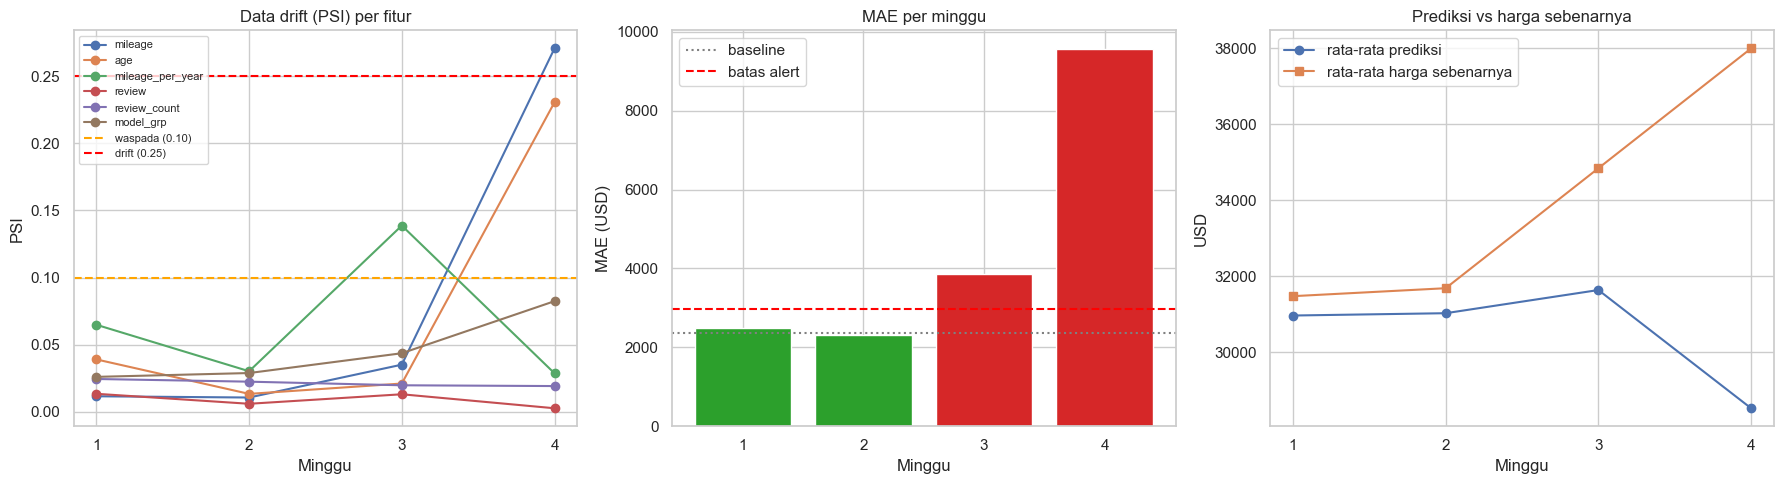

In [51]:
# 12.8 Dashboard monitoring
weeks = [1, 2, 3, 4]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for c in psi_df.columns:
    axes[0].plot(weeks, psi_df[c].values, marker="o", label=c)
axes[0].axhline(0.10, color="orange", ls="--", label="waspada (0.10)")
axes[0].axhline(0.25, color="red", ls="--", label="drift (0.25)")
axes[0].set(title="Data drift (PSI) per fitur", xlabel="Minggu", ylabel="PSI", xticks=weeks)
axes[0].legend(fontsize=8)

axes[1].bar(weeks, perf_df["MAE"].values, color=["tab:green" if s == "OK" else "tab:red" for s in perf_df["status"]])
axes[1].axhline(baseline["MAE"], color="gray", ls=":", label="baseline")
axes[1].axhline(MAE_LIMIT, color="red", ls="--", label="batas alert")
axes[1].set(title="MAE per minggu", xlabel="Minggu", ylabel="MAE (USD)", xticks=weeks)
axes[1].legend()

axes[2].plot(weeks, pred_df["mean_pred"].values, marker="o", label="rata-rata prediksi")
axes[2].plot(weeks, pred_df["mean_actual"].values, marker="s", label="rata-rata harga sebenarnya")
axes[2].set(title="Prediksi vs harga sebenarnya", xlabel="Minggu", ylabel="USD", xticks=weeks)
axes[2].legend()

plt.tight_layout(); plt.show()